# 04 - Annotation : formats, conversions, controle, accord entre annotateurs, erreurs d'etiquette

Ce que l'on apprend :
- un format PIVOT unique (quatre dataclasses) et, pour chaque format, un lecteur et un ecrivain :
  VOC, YOLO, COCO, LabelMe, Label Studio, CVAT, masques PNG. Convertir A vers B = lire A puis
  ecrire B : n formats demandent 2n fonctions, pas n x n convertisseurs ;
- verifier chaque conversion par un aller-retour : un format mal lu ne leve AUCUNE erreur, il
  donne des boites decalees, et l'entrainement "marche" quand meme ;
- passer des masques aux boites, boites orientees et polygones (et revenir) ;
- controler un jeu annote (boites hors image, minuscules, doublons, classes inconnues, images vides) ;
- mesurer l'accord entre deux annotateurs : c'est le plafond de tout modele ;
- laisser un modele designer les etiquettes suspectes (probabilites hors pli).

Donnees : NEU-DET (boites VOC), Magnetic Tile (masques), NEU-CLS (classes) :
`python tools/get_data/get_neu_det.py`, `get_magnetic_tile.py`, `get_neu_cls.py`.
Prerequis : le socle de la toolbox (`pip install -e .`) pour `vtb.viz` et la cellule de controle.
Duree en mode QUICK sur un CPU 2 coeurs : 2 a 3 minutes. Lancer depuis la racine du depot.

**Dans le fil** : ce notebook approfondit l'etape 2 (Importer et explorer : lire et controler les
annotations, mesurer leur qualite) et l'etape 3 (Cataloguer : ramener tout format a un format pivot).
Le fil des 13 etapes, le meme que dans le cours : `ETAPES.md`, a la racine de la toolbox.

## 0. Reglages (etape 1)

Pour ses propres donnees : changer les chemins (et `CLASS_NAMES_TILE` si les masques ont
plusieurs classes). Tout le reste se deduit des fichiers.

In [1]:
import json  # json : lire et ecrire des fichiers JSON (formats COCO, LabelMe, Label Studio)
import math  # math : cosinus, sinus, radians (boites tournees de Label Studio)
import time  # time : chronometre pour mesurer la duree des conversions
import xml.etree.ElementTree as ET  # ElementTree : lire et ecrire du XML (formats VOC et CVAT)
from collections import Counter  # Counter : compte combien de fois apparait chaque valeur
from dataclasses import asdict, dataclass, field  # dataclass : classe conteneur de donnees (on liste ses champs) ; asdict : objet -> dict
from pathlib import Path  # Path : represente un chemin de fichier, fonctionne sous Windows comme sous Linux

import cv2  # OpenCV : lecture d'images, contours, composantes connexes, dessin
import numpy as np  # numpy : calcul sur des tableaux de nombres (une image = un tableau)
import pandas as pd  # pandas : tableaux de donnees (DataFrame) faciles a afficher et a regrouper
import torch  # PyTorch : tenseurs (tableaux de nombres sur CPU ou GPU) et reseaux de neurones (section 7)
from IPython.display import display  # display : affiche joliment un tableau dans le notebook
from PIL import Image  # PIL : lit la taille d'une image sans la decoder entierement
from scipy.optimize import linear_sum_assignment  # algorithme hongrois : meilleur appariement un pour un entre deux listes (section 6)
from sklearn.linear_model import LogisticRegression  # regression logistique : classifieur lineaire qui donne des probabilites (section 7)
from sklearn.metrics import cohen_kappa_score  # kappa de Cohen : accord entre deux annotateurs, corrige du hasard (section 6)
from sklearn.model_selection import StratifiedKFold, cross_val_predict  # validation croisee : predire chaque image sans l'avoir apprise
from sklearn.pipeline import make_pipeline  # enchaine plusieurs etapes (mise a l'echelle puis classifieur) en un seul modele
from sklearn.preprocessing import StandardScaler  # StandardScaler : met chaque variable a moyenne 0 et ecart-type 1
from torchvision import models  # models : reseaux de neurones pre-entraines de torchvision (ici resnet18)

from vtb import viz  # viz : fonctions d'affichage de la toolbox (grilles d'images, boites, masques)

QUICK = True  # True : sous-ensemble d'images pour la section 7 (rapide) ; False : toutes les images de NEU-CLS
SEED = 0  # graine du hasard : memes tirages a chaque execution (resultats reproductibles)
NEU_IMAGES = Path("data/raw/neu_det/IMAGES")  # NEU-DET : images 200 x 200 en niveaux de gris, 6 classes de defauts
NEU_XML = Path("data/raw/neu_det/ANNOTATIONS")  # un fichier XML Pascal VOC par image, de meme nom (les boites des defauts)
# Magnetic Tile : MT_<type>/Imgs/x.jpg + masque binaire x.png a cote (defaut marque pixel par pixel)
TILE_ROOT = Path("data/raw/magnetic_tile")
TILE_TYPES = ["MT_Blowhole", "MT_Break", "MT_Crack", "MT_Fray", "MT_Uneven"]  # les 5 dossiers de defauts de Magnetic Tile utilises ici
NEU_CLS = Path("data/raw/neu_cls_flat")  # NEU-CLS : un sous-dossier par classe (classification, section 7)
NOISE_RATE = 0.05  # section 7 : part d'etiquettes volontairement faussees (5 %)
PER_CLASS = 100 if QUICK else None  # section 7 : images par classe (None = toutes)
# calcule sur la carte graphique (GPU, "cuda") si elle existe, sinon sur le processeur (CPU)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
OUT = Path("outputs/notebooks/04_annotation")  # dossier des fichiers ecrits par ce notebook
OUT.mkdir(parents=True, exist_ok=True)  # cree le dossier et ses parents ; pas d'erreur s'il existe deja
IMAGE_EXTENSIONS = {".bmp", ".jpg", ".jpeg", ".png", ".tif", ".tiff"}  # extensions de fichiers reconnues comme images
viz.setup_notebook(dpi=80, fmt="jpeg")  # figures a 80 points par pouce, en jpeg (notebook plus leger)
rng = np.random.default_rng(SEED)  # generateur aleatoire numpy avec graine, utilise par toutes les simulations du notebook

## 1. Le format pivot (etape 3)

Toute la suite ne manipule que ces quatre classes. Coordonnees : toujours en PIXELS de l'image
d'origine, origine en haut a gauche, x vers la droite, y vers le bas. Les formats normalises
(YOLO, Label Studio en %) sont convertis a la lecture et a l'ecriture, nulle part ailleurs.
Les champs sont ceux de `vtb.annotate.schema` : un fichier ecrit ici est relu par la production.

In [2]:
@dataclass  # @dataclass : Python ecrit seul le constructeur Box(label, x1, y1, x2, y2) a partir des champs
class Box:  # boite alignee sur les axes (rectangle droit) : la forme de base de la detection
    """Boite alignee sur les axes, coins en pixels ; score rempli pour une prediction."""

    label: str  # nom de la classe du defaut
    x1: float  # bord gauche, en pixels
    y1: float  # bord haut, en pixels (l'axe y descend)
    x2: float  # bord droit
    y2: float  # bord bas
    score: float | None = None  # confiance du modele pour une prediction ; None pour une annotation humaine

    @property  # @property : width se lit comme un champ (box.width), sans parentheses
    def width(self) -> float:  # largeur de la boite en pixels
        return self.x2 - self.x1  # bord droit - bord gauche

    @property  # meme principe pour la hauteur
    def height(self) -> float:  # hauteur de la boite en pixels
        return self.y2 - self.y1  # bord bas - bord haut

    def clipped(self, width: int, height: int) -> "Box":  # renvoie une copie de la boite ramenee a l'interieur de l'image (width x height)
        # coins bornes : x1, y1 >= 0 et x2 <= largeur, y2 <= hauteur ; classe et score gardes
        return Box(self.label, max(0.0, self.x1), max(0.0, self.y1), min(float(width), self.x2), min(float(height), self.y2), self.score)


@dataclass  # constructeur genere automatiquement a partir des champs
class RotatedBox:  # boite orientee : rectangle tourne, pour un defaut en biais
    """Boite orientee (rayure en biais) : centre, taille, angle en degres (convention OpenCV)."""

    label: str  # nom de la classe
    cx: float  # x du centre
    cy: float  # y du centre
    w: float  # largeur (avant rotation)
    h: float  # hauteur (avant rotation)
    angle: float  # angle de rotation en degres (convention OpenCV)
    score: float | None = None  # confiance du modele, None pour une annotation

    def corners(self) -> list[tuple[float, float]]:  # renvoie les 4 coins (x, y) de la boite tournee
        # cv2.boxPoints calcule les 4 coins a partir de (centre, taille, angle) ; convertis en nombres Python
        return [(float(x), float(y)) for x, y in cv2.boxPoints(((self.cx, self.cy), (self.w, self.h), self.angle))]


@dataclass  # constructeur genere automatiquement
class Polygon:  # polygone : contour d'un objet (segmentation d'instance : chaque objet a sa forme exacte)
    """Contour d'un objet (segmentation d'instance)."""

    label: str  # nom de la classe
    points: list[tuple[float, float]]  # sommets (x, y) en pixels, dans l'ordre du contour
    score: float | None = None  # confiance du modele, None pour une annotation

    def bounding_box(self) -> Box:  # renvoie la boite alignee qui englobe le polygone
        xs, ys = [p[0] for p in self.points], [p[1] for p in self.points]  # les x et les y de tous les sommets
        return Box(self.label, min(xs), min(ys), max(xs), max(ys), self.score)  # min et max des x et des y = coins de la boite englobante


@dataclass  # constructeur genere automatiquement
class ImageAnnotation:  # le format PIVOT : tout ce qu'on sait d'une image ; toutes les conversions passent par lui
    """Tout ce qu'on sait d'une image : etiquettes d'image, boites, boites orientees, polygones, masque."""

    image_path: str  # chemin de l'image
    width: int  # largeur en pixels
    height: int  # hauteur en pixels
    # etiquettes d'image (classification) ; default_factory : une liste vide NEUVE pour chaque objet
    labels: list[str] = field(default_factory=list)
    boxes: list[Box] = field(default_factory=list)  # boites alignees
    rotated: list[RotatedBox] = field(default_factory=list)  # boites orientees
    polygons: list[Polygon] = field(default_factory=list)  # polygones
    mask_path: str | None = None  # chemin du masque PNG s'il y en a un, sinon None

    def object_labels(self) -> list[str]:  # renvoie les classes de tous les objets de l'image (boites, boites orientees, polygones)
        return [o.label for o in (*self.boxes, *self.rotated, *self.polygons)]  # * deplie les trois listes en une seule suite

    def main_label(self, empty: str = "background") -> str:  # renvoie LA classe principale de l'image ; "background" si l'image n'a rien
        """Etiquette d'image, sinon la classe la plus frequente des objets : sert a stratifier un decoupage."""
        if self.labels:  # si l'image a une etiquette d'image...
            return self.labels[0]  # ...c'est elle
        counts = Counter(self.object_labels())  # sinon : compte les objets par classe
        return counts.most_common(1)[0][0] if counts else empty  # classe la plus frequente, ou "background" si aucun objet


# renvoie toutes les classes presentes dans un jeu, triees (l'ordre fixe les indices YOLO / COCO)
def class_names_of(annotations: list[ImageAnnotation]) -> list[str]:
    """Toutes les classes presentes, triees : l'ordre fixe les indices (YOLO, COCO)."""
    names: set[str] = set()  # ensemble (set) : chaque nom n'y est garde qu'une fois
    for ann in annotations:  # pour chaque image annotee
        names.update(ann.labels)  # ajoute ses etiquettes d'image
        names.update(ann.object_labels())  # et les classes de ses objets
    return sorted(names)  # liste triee par ordre alphabetique


# renvoie les images d'un dossier (sous-dossiers compris), triees
def list_images(folder: Path, extensions: set[str] = IMAGE_EXTENSIONS) -> list[Path]:
    """Images d'un dossier, triees (l'ordre du disque differe entre Windows et Linux)."""
    # rglob("*") parcourt tout ; garde les fichiers dont l'extension (en minuscules) est une image
    return sorted(p for p in Path(folder).rglob("*") if p.is_file() and p.suffix.lower() in extensions)


def image_size(path: str | Path) -> tuple[int, int]:  # renvoie (largeur, hauteur) d'une image
    """(largeur, hauteur) en lisant seulement l'en-tete du fichier."""
    with Image.open(path) as handle:  # ouvre l'image (seul l'en-tete est lu) ; with la referme a la fin du bloc
        return handle.size  # (largeur, hauteur) en pixels


def read_gray(path: str | Path) -> np.ndarray:  # lit une image en niveaux de gris ; renvoie un tableau numpy 2D, valeurs 0-255
    """Lecture robuste aux chemins Windows avec accents (imdecode au lieu d'imread)."""
    # fromfile lit les octets (chemins avec accents acceptes), imdecode les decode en image grise
    return cv2.imdecode(np.fromfile(str(path), np.uint8), cv2.IMREAD_GRAYSCALE)

## 2. Pascal VOC : un XML par image, coins en pixels (etapes 2 et 3)

Le champ `<path>` du XML est souvent faux (chemin de la machine de l'annotateur) : on apparie
image et XML par le NOM de fichier. Les boites qui debordent d'un pixel sont ramenees dans l'image.

In [3]:
# lit un XML VOC ; renvoie l'ImageAnnotation de l'image (boites en pixels)
def read_voc_file(xml_path: Path, image_path: Path) -> ImageAnnotation:
    root = ET.parse(xml_path).getroot()  # lit le XML et prend sa balise racine <annotation>
    # taille de l'image lue dans <size> (float puis int : accepte aussi "200.0")
    width, height = int(float(root.findtext("size/width"))), int(float(root.findtext("size/height")))
    boxes = []  # boites a remplir
    for obj in root.iter("object"):  # pour chaque objet annote
        b = obj.find("bndbox")  # la balise des coordonnees
        coords = [float(b.findtext(k)) for k in ("xmin", "ymin", "xmax", "ymax")]  # xmin, ymin, xmax, ymax en nombres decimaux
        # nom de classe (espaces retires) + coordonnees -> Box, ramenee dans l'image
        boxes.append(Box(obj.findtext("name").strip(), *coords).clipped(width, height))
    return ImageAnnotation(str(image_path), width, height, boxes=boxes)  # l'annotation de l'image au format pivot


# lit tout un dossier VOC ; renvoie une ImageAnnotation par image
def read_voc_folder(images_dir: Path, xml_dir: Path) -> list[ImageAnnotation]:
    annotations = []  # liste a remplir
    for image_path in list_images(images_dir):  # pour chaque image (on part des images, pas des XML)
        xml_path = Path(xml_dir) / f"{image_path.stem}.xml"  # XML de meme nom : on apparie par le NOM de fichier, pas par le champ <path>
        if not xml_path.exists():  # image sans XML : erreur explicite plutot qu'une image comptee a tort comme saine
            raise FileNotFoundError(f"annotation VOC absente pour {image_path.name}")  # arrete tout en nommant l'image fautive
        annotations.append(read_voc_file(xml_path, image_path))  # lit le XML et garde le resultat
    return annotations  # une annotation par image


def write_voc_folder(annotations: list[ImageAnnotation], xml_dir: Path) -> None:  # ecrit un XML VOC par image (boites seulement)
    """Boites seulement : VOC ne sait pas representer polygones ni boites orientees."""
    Path(xml_dir).mkdir(parents=True, exist_ok=True)  # cree le dossier de sortie s'il n'existe pas
    for ann in annotations:  # pour chaque image
        root = ET.Element("annotation")  # balise racine du XML
        ET.SubElement(root, "filename").text = Path(ann.image_path).name  # <filename> : nom du fichier image
        size = ET.SubElement(root, "size")  # <size> : taille de l'image
        # largeur, hauteur, nombre de canaux (3 par convention)
        for key, value in (("width", ann.width), ("height", ann.height), ("depth", 3)):
            ET.SubElement(size, key).text = str(value)  # une sous-balise par valeur, ecrite en texte
        for box in ann.boxes:  # pour chaque boite
            obj = ET.SubElement(root, "object")  # une balise <object> par boite
            ET.SubElement(obj, "name").text = box.label  # <name> : la classe
            bnd = ET.SubElement(obj, "bndbox")  # <bndbox> : les coordonnees
            # associe chaque nom de coordonnee a sa valeur
            for key, value in zip(("xmin", "ymin", "xmax", "ymax"), (box.x1, box.y1, box.x2, box.y2)):
                ET.SubElement(bnd, key).text = f"{value:.1f}"  # ecrite avec une decimale
        # ecrit le XML sous le nom de l'image, avec l'extension .xml
        ET.ElementTree(root).write(Path(xml_dir) / f"{Path(ann.image_path).stem}.xml", encoding="utf-8", xml_declaration=True)


reference = read_voc_folder(NEU_IMAGES, NEU_XML)  # LA reference : NEU-DET lu depuis ses XML d'origine
CLASS_NAMES = class_names_of(reference)  # les classes du jeu, triees : l'ordre donne les indices
# nombre de boites par classe (une entree par boite), trie par nom
counts = pd.Series([b.label for a in reference for b in a.boxes]).value_counts().sort_index()
print(f"{len(reference)} images | {int(counts.sum())} boites | {len(CLASS_NAMES)} classes")  # resume : images, boites, classes
# tableau par classe : nombre de boites et nombre d'images (classe principale de l'image)
pd.DataFrame({"boites": counts, "images": pd.Series([a.main_label() for a in reference]).value_counts().sort_index()})

1770 images | 4126 boites | 6 classes


,boites,images
crazing,678,295
inclusion,1001,308
patches,866,302
pitted_surface,423,284
rolled-in_scale,620,295
scratches,538,286


## 3. Les autres formats, ecrits et relus a la main (etapes 2 et 3)

| format | fichiers | coordonnees | ce qu'il represente |
|---|---|---|---|
| YOLO | un .txt par image + liste des classes | normalisees [0, 1], centre + taille | boites, boites orientees (4 coins), polygones |
| COCO | un JSON pour tout le jeu | pixels, `bbox = [x, y, l, h]` | boites, polygones (`segmentation`) |
| LabelMe / X-AnyLabeling | un JSON par image | pixels, points | rectangle, polygone, rotation (4 coins) |
| Label Studio | un JSON (liste de taches) | POURCENTAGE, rotation horaire autour du coin haut gauche | boites, boites tournees, polygones, choix |
| CVAT 1.1 | un XML pour la tache | pixels, rotation horaire autour du centre | boites, boites tournees, polygones, tags |

In [4]:
# ecrit un .txt YOLO par image + classes.txt ; coordonnees normalisees (divisees par la taille : dans [0, 1])
def write_yolo_folder(annotations: list[ImageAnnotation], labels_dir: Path, class_names: list[str]) -> None:
    """Un .txt par image : `classe cx cy w h` normalises ; une image sans objet a un .txt vide (negatif)."""
    labels_dir.mkdir(parents=True, exist_ok=True)  # cree le dossier de sortie
    index = {name: k for k, name in enumerate(class_names)}  # nom de classe -> indice (sa position dans class_names)
    for ann in annotations:  # pour chaque image
        w, h = float(ann.width), float(ann.height)  # taille de l'image en decimal, pour normaliser
        lines = []  # lignes du .txt de cette image
        for b in ann.boxes:  # pour chaque boite
            b = b.clipped(ann.width, ann.height)  # ramenee dans l'image d'abord
            # centre x, centre y, largeur, hauteur, divises par la taille de l'image
            values = [(b.x1 + b.x2) / 2 / w, (b.y1 + b.y2) / 2 / h, b.width / w, b.height / h]
            # "classe cx cy w h", chaque valeur bornee a [0, 1] et ecrite avec 6 decimales
            lines.append(f"{index[b.label]} " + " ".join(f"{min(max(v, 0.0), 1.0):.6f}" for v in values))
        for r in ann.rotated:  # boites orientees (YOLO-OBB) : les quatre coins normalises
            lines.append(  # ajoute la ligne :
                # "classe x1 y1 x2 y2 x3 y3 x4 y4", coins normalises et bornes a [0, 1]
                f"{index[r.label]} " + " ".join(f"{min(max(x / w, 0), 1):.6f} {min(max(y / h, 0), 1):.6f}" for x, y in r.corners())
            )
        for p in ann.polygons:  # polygones (YOLO-seg) : tous les sommets normalises
            # "classe x1 y1 x2 y2 ..." pour chaque sommet du polygone
            lines.append(f"{index[p.label]} " + " ".join(f"{min(max(x / w, 0), 1):.6f} {min(max(y / h, 0), 1):.6f}" for x, y in p.points))
        # ecrit le .txt ; image sans objet = fichier vide (un negatif, utile a l'entrainement)
        (labels_dir / f"{Path(ann.image_path).stem}.txt").write_text("\n".join(lines) + ("\n" if lines else ""), encoding="utf-8")
    # liste des classes, une par ligne : l'ordre donne les indices
    (labels_dir / "classes.txt").write_text("\n".join(class_names) + "\n", encoding="utf-8")


# lit un dossier YOLO ; task dit comment lire chaque ligne ; renvoie une ImageAnnotation par image
def read_yolo_folder(images_dir: Path, labels_dir: Path, class_names: list[str], task: str = "detect") -> list[ImageAnnotation]:
    """task : detect (4 valeurs), obb (8 valeurs) ou segment (polygone). Sans .txt : image sans objet."""
    annotations = []  # liste a remplir
    for image_path in list_images(images_dir):  # pour chaque image
        width, height = image_size(image_path)  # taille reelle de l'image : YOLO ne la stocke pas
        ann = ImageAnnotation(str(image_path), width, height)  # annotation vide a remplir
        txt = labels_dir / f"{image_path.stem}.txt"  # le .txt de meme nom
        # pour chaque ligne du .txt (aucune si le fichier n'existe pas : image sans objet)
        for line in txt.read_text(encoding="utf-8").splitlines() if txt.exists() else []:
            if not line.strip():  # ligne vide...
                continue  # ...ignoree
            values = line.split()  # decoupe la ligne aux espaces
            # 1re valeur = indice de classe -> nom ; le reste = coordonnees normalisees
            label, coords = class_names[int(values[0])], [float(v) for v in values[1:]]
            if task == "detect":  # boite alignee : cx cy w h
                # remise en pixels (x par la largeur, y par la hauteur)
                cx, cy, bw, bh = coords[0] * width, coords[1] * height, coords[2] * width, coords[3] * height
                # centre +/- demi-taille = coins de la boite
                ann.boxes.append(Box(label, cx - bw / 2, cy - bh / 2, cx + bw / 2, cy + bh / 2))
            elif task == "obb":  # boite orientee : 4 coins
                pts = np.array(coords, np.float32).reshape(-1, 2) * [width, height]  # les 8 valeurs en 4 points (x, y), remis en pixels
                # plus petit rectangle tourne qui contient les 4 points : centre, taille, angle
                (cx, cy), (rw, rh), angle = cv2.minAreaRect(pts.astype(np.float32))
                ann.rotated.append(RotatedBox(label, float(cx), float(cy), float(rw), float(rh), float(angle)))  # converti en RotatedBox
            else:  # sinon (segment) : polygone
                # valeurs prises 2 par 2 (x, y) et remises en pixels
                ann.polygons.append(Polygon(label, [(coords[i] * width, coords[i + 1] * height) for i in range(0, len(coords), 2)]))
        annotations.append(ann)  # garde l'annotation de l'image
    return annotations  # une annotation par image


# ecrit un seul JSON COCO pour tout le jeu (images, categories, annotations)
def write_coco(annotations: list[ImageAnnotation], path: Path, class_names: list[str]) -> None:
    """Un JSON : images, categories (ids a partir de 1), annotations (bbox = x, y, largeur, hauteur)."""
    # nom -> identifiant COCO (a partir de 1 : 0 est souvent reserve au fond)
    category = {name: k + 1 for k, name in enumerate(class_names)}
    images, objects = [], []  # les listes "images" et "annotations" du JSON
    for image_id, ann in enumerate(annotations, start=1):  # pour chaque image, avec un identifiant a partir de 1
        # fiche de l'image : identifiant, nom de fichier, taille
        images.append({"id": image_id, "file_name": Path(ann.image_path).name, "width": ann.width, "height": ann.height})
        for b in ann.boxes:  # pour chaque boite
            objects.append(  # une annotation COCO par boite :
                {  # dictionnaire de l'objet
                    "image_id": image_id,  # image a laquelle appartient l'objet
                    "category_id": category[b.label],  # identifiant de la classe
                    "bbox": [b.x1, b.y1, b.width, b.height],  # COCO : [x, y, largeur, hauteur] (coin haut-gauche + taille), pas xyxy
                    "area": b.width * b.height,  # surface en pixels carres
                    "iscrowd": 0,  # 0 = un seul objet (1 = foule, codee autrement)
                    "segmentation": [],  # pas de contour pour une simple boite
                }
            )
        for p in ann.polygons:  # pour chaque polygone
            bb = p.bounding_box()  # sa boite englobante (COCO en veut une aussi)
            objects.append(  # une annotation COCO par polygone :
                {  # dictionnaire de l'objet
                    "image_id": image_id,  # image a laquelle appartient l'objet
                    "category_id": category[p.label],  # identifiant de la classe
                    "bbox": [bb.x1, bb.y1, bb.width, bb.height],  # boite englobante [x, y, largeur, hauteur]
                    "area": float(cv2.contourArea(np.array(p.points, np.float32))),  # surface reelle du polygone (cv2.contourArea)
                    "iscrowd": 0,  # un seul objet
                    # sommets a plat [x1, y1, x2, y2, ...], dans une liste de contours
                    "segmentation": [[v for pt in p.points for v in pt]],
                }
            )
    for k, obj in enumerate(objects, start=1):  # numerote les objets a partir de 1...
        obj["id"] = k  # ...COCO veut un identifiant unique par annotation
    # liste des categories ; supercategory = groupe parent (ici "defect")
    categories = [{"id": category[n], "name": n, "supercategory": "defect"} for n in class_names]
    # ecrit le JSON complet en un seul fichier
    path.write_text(json.dumps({"images": images, "annotations": objects, "categories": categories}), encoding="utf-8")


def read_coco(images_dir: Path, path: Path) -> list[ImageAnnotation]:  # lit un JSON COCO ; renvoie une ImageAnnotation par image
    payload = json.loads(path.read_text(encoding="utf-8"))  # le JSON entier en dictionnaire Python
    names = {c["id"]: c["name"] for c in payload["categories"]}  # identifiant de categorie -> nom de classe
    # identifiant d'image -> ImageAnnotation vide (chemin, largeur, hauteur)
    by_id = {im["id"]: ImageAnnotation(str(images_dir / im["file_name"]), int(im["width"]), int(im["height"])) for im in payload["images"]}
    for obj in payload["annotations"]:  # pour chaque objet annote
        ann, label = by_id[obj["image_id"]], names[obj["category_id"]]  # son image et le nom de sa classe
        # masque compresse (RLE : iscrowd = 1 ou segmentation en dict)...
        if obj.get("iscrowd", 0) == 1 or isinstance(obj.get("segmentation"), dict):
            continue  # ...ignore ici : passer par les masques (section 4)
        if obj.get("segmentation"):  # si l'objet a un contour : polygone(s)
            for flat in obj["segmentation"]:  # pour chaque contour (liste a plat x1, y1, x2, y2...)
                # valeurs prises 2 par 2 -> sommets (x, y)
                ann.polygons.append(Polygon(label, [(float(flat[i]), float(flat[i + 1])) for i in range(0, len(flat), 2)]))
        else:  # sinon : simple boite
            x, y, w, h = (float(v) for v in obj["bbox"])  # bbox COCO : coin haut-gauche + taille
            ann.boxes.append(Box(label, x, y, x + w, y + h))  # converti en coins xyxy
    return list(by_id.values())  # les annotations, dans l'ordre des images du JSON


# ecrit un JSON LabelMe par image (rectangles et polygones)
def write_labelme_folder(annotations: list[ImageAnnotation], json_dir: Path) -> None:
    """Un JSON par image (format LabelMe, lu aussi par X-AnyLabeling) ; pas d'image en base64 dedans."""
    json_dir.mkdir(parents=True, exist_ok=True)  # cree le dossier de sortie
    for ann in annotations:  # pour chaque image
        # un rectangle LabelMe = 2 points (coin haut-gauche, coin bas-droit) par boite
        shapes = [{"label": b.label, "points": [[b.x1, b.y1], [b.x2, b.y2]], "shape_type": "rectangle", "flags": {}} for b in ann.boxes]
        # plus un polygone par contour (tous les sommets)
        shapes += [{"label": p.label, "points": [list(pt) for pt in p.points], "shape_type": "polygon", "flags": {}} for p in ann.polygons]
        payload = {  # contenu du fichier :
            "version": "5.4.1",  # version du format LabelMe
            "flags": {},  # drapeaux d'image (aucun)
            "shapes": shapes,  # les formes
            "imagePath": Path(ann.image_path).name,  # nom de l'image (relatif au JSON)
            "imageData": None,  # None : pas d'image codee en base64 dans le JSON (fichier leger)
            "imageHeight": ann.height,  # hauteur
            "imageWidth": ann.width,  # largeur
        }
        # ecrit le JSON au nom de l'image
        (json_dir / f"{Path(ann.image_path).stem}.json").write_text(json.dumps(payload), encoding="utf-8")


# lit un dossier de JSON LabelMe ; renvoie une ImageAnnotation par fichier
def read_labelme_folder(images_dir: Path, json_dir: Path) -> list[ImageAnnotation]:
    annotations = []  # liste a remplir
    for path in sorted(json_dir.glob("*.json")):  # pour chaque JSON, par ordre alphabetique
        payload = json.loads(path.read_text(encoding="utf-8"))  # lit le JSON
        # annotation vide : image cherchee dans images_dir par son nom, taille lue dans le JSON
        ann = ImageAnnotation(str(images_dir / Path(payload["imagePath"]).name), int(payload["imageWidth"]), int(payload["imageHeight"]))
        for shape in payload["shapes"]:  # pour chaque forme dessinee
            points = [(float(x), float(y)) for x, y in shape["points"]]  # ses points en nombres decimaux
            if shape["shape_type"] == "rectangle":  # rectangle : LabelMe ne garantit pas l'ordre des deux coins...
                (xa, ya), (xb, yb) = points  # les deux coins
                # ...donc min / max pour obtenir haut-gauche et bas-droit
                ann.boxes.append(Box(shape["label"], min(xa, xb), min(ya, yb), max(xa, xb), max(ya, yb)))
            elif shape["shape_type"] == "polygon" and len(points) >= 3:  # polygone d'au moins 3 points (sinon ce n'est pas une surface)
                ann.polygons.append(Polygon(shape["label"], points))  # garde le polygone
        annotations.append(ann)  # garde l'annotation de l'image
    return annotations  # une annotation par fichier


# ecrit un JSON de taches Label Studio ; coordonnees en POURCENTAGE de l'image
def write_labelstudio(annotations: list[ImageAnnotation], path: Path) -> None:
    """Taches Label Studio (format d'export "JSON") : coordonnees en POURCENTAGE de l'image."""
    tasks = []  # une tache par image
    for ann in annotations:  # pour chaque image
        w, h = float(ann.width), float(ann.height)  # taille en decimal, pour les pourcentages
        # champs communs a chaque resultat : noms du controle et de l'image, taille d'origine
        common = {"from_name": "label", "to_name": "image", "original_width": ann.width, "original_height": ann.height}
        result = [  # une region (rectangle) par boite :
            {  # un resultat Label Studio
                "type": "rectanglelabels",  # type de region : rectangle etiquete
                **common,  # ** recopie les champs communs dans ce dict
                "value": {  # geometrie et classe :
                    "x": b.x1 / w * 100,  # bord gauche en % de la largeur
                    "y": b.y1 / h * 100,  # bord haut en % de la hauteur
                    "width": b.width / w * 100,  # largeur en %
                    "height": b.height / h * 100,  # hauteur en %
                    "rotation": 0,  # pas de rotation
                    "rectanglelabels": [b.label],  # la classe, dans une liste
                },
            }
            for b in ann.boxes  # pour chaque boite de l'image
        ]
        # tache : chemin de l'image + une annotation qui contient les regions
        tasks.append({"data": {"image": Path(ann.image_path).as_posix()}, "annotations": [{"result": result}]})
    path.write_text(json.dumps(tasks), encoding="utf-8")  # ecrit toutes les taches dans un seul JSON


# lit un export JSON Label Studio ; renvoie une ImageAnnotation par tache
def read_labelstudio(images_dir: Path, path: Path) -> list[ImageAnnotation]:
    """Export JSON Label Studio : on garde la derniere annotation non annulee de chaque tache.

    Un rectangle tourne est donne par son coin haut gauche (avant rotation), sa taille et une
    rotation HORAIRE autour de ce coin : on retrouve le centre par la geometrie.
    """
    annotations = []  # liste a remplir
    for task in json.loads(path.read_text(encoding="utf-8")):  # pour chaque tache (une image)
        reference_path = task["data"]["image"]  # chemin de l'image : chemin, URL /data/local-files/?d=... ou /data/upload/...
        # le chemin s'il existe, sinon l'image de meme nom dans images_dir
        image_path = Path(reference_path) if Path(reference_path).exists() else images_dir / Path(reference_path).name
        # annotations de la tache, sans celles annulees
        entries = [a for a in task.get("annotations", []) if not a.get("was_cancelled", False)]
        result = entries[-1]["result"] if entries else []  # la derniere (la plus recente), ou rien
        # taille d'origine donnee par le 1er resultat, sinon lue dans l'image
        width, height = (result[0]["original_width"], result[0]["original_height"]) if result else image_size(image_path)
        ann = ImageAnnotation(str(image_path), int(width), int(height))  # annotation vide a remplir
        for item in result:  # pour chaque region annotee
            v = item["value"]  # sa geometrie et sa classe
            if item["type"] == "rectanglelabels":  # si c'est un rectangle
                # pourcentages -> pixels : coin haut-gauche (avant rotation) et taille
                x, y, bw, bh = v["x"] / 100 * width, v["y"] / 100 * height, v["width"] / 100 * width, v["height"] / 100 * height
                angle = float(v.get("rotation", 0) or 0)  # rotation en degres (0 si absente ou vide)
                if abs(angle % 360) < 1e-9:  # pas de rotation (a un tour pres)...
                    ann.boxes.append(Box(v["rectanglelabels"][0], x, y, x + bw, y + bh))  # ...boite alignee
                else:  # sinon : rectangle tourne autour de son coin haut-gauche
                    t = math.radians(angle)  # degres -> radians (ce qu'attendent cos et sin)
                    cx = x + (bw * math.cos(t) - bh * math.sin(t)) / 2  # centre = coin + demi-diagonale tournee de t (coordonnee x)...
                    cy = y + (bw * math.sin(t) + bh * math.cos(t)) / 2  # ...(coordonnee y) ; rotation horaire a l'ecran car l'axe y descend
                    # boite orientee definie par son centre, sa taille et son angle
                    ann.rotated.append(RotatedBox(v["rectanglelabels"][0], cx, cy, bw, bh, angle % 360))
            elif item["type"] == "polygonlabels":  # si c'est un polygone
                # sommets en % -> pixels
                ann.polygons.append(Polygon(v["polygonlabels"][0], [(p[0] / 100 * width, p[1] / 100 * height) for p in v["points"]]))
            elif item["type"] == "choices":  # si c'est un choix de classe pour toute l'image
                ann.labels.extend(v["choices"])  # etiquettes d'image (classification)
        annotations.append(ann)  # garde l'annotation de l'image
    return annotations  # une annotation par tache


def write_cvat(annotations: list[ImageAnnotation], path: Path, class_names: list[str]) -> None:  # ecrit un XML CVAT 1.1 pour toute la tache
    """CVAT for images 1.1 : un XML pour toute la tache (aussi un format d'IMPORT de pre-annotations)."""
    root = ET.Element("annotations")  # balise racine <annotations>
    ET.SubElement(root, "version").text = "1.1"  # <version>1.1</version>
    labels = ET.SubElement(ET.SubElement(ET.SubElement(root, "meta"), "task"), "labels")  # <meta><task><labels> : la liste des classes
    for name in class_names:  # pour chaque classe
        ET.SubElement(ET.SubElement(labels, "label"), "name").text = name  # <label><name>classe</name></label>
    for k, ann in enumerate(annotations):  # pour chaque image, avec son numero
        # <image> : numero, nom, largeur, hauteur (attributs ecrits en texte)
        node = ET.SubElement(root, "image", id=str(k), name=Path(ann.image_path).name, width=str(ann.width), height=str(ann.height))
        for b in ann.boxes:  # pour chaque boite
            ET.SubElement(  # une balise <box> dans l'image :
                node,  # l'element parent : l'image
                "box",  # nom de la balise
                label=b.label,  # classe
                xtl=f"{b.x1:.4f}",  # x haut-gauche (4 decimales)
                ytl=f"{b.y1:.4f}",  # y haut-gauche
                xbr=f"{b.x2:.4f}",  # x bas-droit
                ybr=f"{b.y2:.4f}",  # y bas-droit
                occluded="0",  # objet non cache (attribut exige par CVAT)
            )
    ET.ElementTree(root).write(path, encoding="utf-8", xml_declaration=True)  # ecrit le fichier XML


def read_cvat(images_dir: Path, path: Path) -> list[ImageAnnotation]:  # lit un XML CVAT 1.1 ; renvoie une ImageAnnotation par image
    """Une box avec un attribut rotation (degres, horaire, autour du centre) devient une RotatedBox."""
    annotations = []  # liste a remplir
    for node in ET.parse(path).getroot().iter("image"):  # pour chaque balise <image>
        # annotation vide : chemin dans images_dir, taille lue dans les attributs
        ann = ImageAnnotation(str(images_dir / node.get("name")), int(node.get("width")), int(node.get("height")))
        ann.labels += [tag.get("label") for tag in node.iter("tag")]  # les <tag> = etiquettes d'image
        for box in node.iter("box"):  # pour chaque boite
            x1, y1, x2, y2 = (float(box.get(k)) for k in ("xtl", "ytl", "xbr", "ybr"))  # coins haut-gauche (tl) et bas-droit (br)
            rotation = float(box.get("rotation", 0) or 0)  # rotation en degres (0 si absente)
            if abs(rotation % 360) < 1e-9:  # pas de rotation...
                ann.boxes.append(Box(box.get("label"), x1, y1, x2, y2))  # ...boite alignee
            else:  # sinon : rotation autour du centre...
                # ...centre = milieu des coins, taille = ecarts, angle ramene dans [0, 360)
                ann.rotated.append(RotatedBox(box.get("label"), (x1 + x2) / 2, (y1 + y2) / 2, x2 - x1, y2 - y1, rotation % 360))
        for poly in node.iter("polygon"):  # pour chaque polygone
            # "x1,y1;x2,y2;..." -> liste de (x, y)
            points = [tuple(float(v) for v in pair.split(",")) for pair in poly.get("points").split(";")]
            ann.polygons.append(Polygon(poly.get("label"), points))  # garde le polygone
        annotations.append(ann)  # garde l'annotation de l'image
    return annotations  # une annotation par image

### La chaine de conversions, verifiee a chaque etape

VOC -> YOLO -> COCO -> LabelMe -> Label Studio -> CVAT -> VOC : chaque format est ecrit a partir du
precedent puis relu, et compare a la reference VOC. Tolerance 0,01 pixel (YOLO garde 6 decimales
normalisees, soit 0,0002 pixel sur 200 pixels). Une seule difference = une conversion a corriger
AVANT d'entrainer.

In [5]:
# compare deux jeux d'annotations ; renvoie la liste des differences lisibles
def differences(a: list[ImageAnnotation], b: list[ImageAnnotation], tol: float = 1e-2) -> list[str]:
    """Differences lisibles entre deux jeux (images appariees par nom) ; liste vide = identiques a tol pixel pres."""
    other = {Path(x.image_path).name: x for x in b}  # nom de fichier -> annotation du second jeu
    # liste des differences ; commence par l'ecart de nombre d'images s'il y en a un
    issues = [] if len(a) == len(b) else [f"{len(a)} images != {len(b)}"]
    for x in a:  # pour chaque image du premier jeu
        y = other.get(Path(x.image_path).name)  # la meme image dans le second jeu (None si absente)
        if y is None:  # image absente...
            issues.append(f"{Path(x.image_path).name} absente")  # ...notee
            continue  # passe a l'image suivante
        if (x.width, x.height) != (y.width, y.height) or sorted(x.labels) != sorted(y.labels):  # taille ou etiquettes d'image differentes ?
            issues.append(f"{Path(x.image_path).name} : taille ou etiquettes")  # notee
        if len(x.boxes) != len(y.boxes):  # nombre de boites different...
            issues.append(f"{Path(x.image_path).name} : {len(x.boxes)} boites != {len(y.boxes)}")  # ...note
            continue  # inutile de comparer boite a boite
        for bx, by in zip(x.boxes, y.boxes):  # compare les boites dans l'ordre (meme ordre attendu)
            # classe differente ou un coin decale de plus de tol pixels ?
            if bx.label != by.label or max(abs(bx.x1 - by.x1), abs(bx.y1 - by.y1), abs(bx.x2 - by.x2), abs(bx.y2 - by.y2)) > tol:
                issues.append(f"{Path(x.image_path).name} : boite {bx} != {by}")  # note la boite fautive
    return issues  # liste vide = identiques


chain = [  # la chaine de conversions : (nom, fonction d'ecriture, fonction de lecture)
    (  # YOLO :
        "yolo",  # nom du format
        lambda anns: write_yolo_folder(anns, OUT / "yolo", CLASS_NAMES),  # lambda = petite fonction sans nom : ecrit le jeu en YOLO
        lambda: read_yolo_folder(NEU_IMAGES, OUT / "yolo", CLASS_NAMES),  # relit le dossier YOLO
    ),
    (  # COCO :
        "coco",  # nom du format
        lambda anns: write_coco(anns, OUT / "neu_det.coco.json", CLASS_NAMES),  # ecrit le JSON COCO
        lambda: read_coco(NEU_IMAGES, OUT / "neu_det.coco.json"),  # le relit
    ),
    # LabelMe : ecriture puis relecture
    ("labelme", lambda anns: write_labelme_folder(anns, OUT / "labelme"), lambda: read_labelme_folder(NEU_IMAGES, OUT / "labelme")),
    (  # Label Studio :
        "labelstudio",  # nom du format
        lambda anns: write_labelstudio(anns, OUT / "labelstudio.json"),  # ecrit le JSON Label Studio
        lambda: read_labelstudio(NEU_IMAGES, OUT / "labelstudio.json"),  # le relit
    ),
    # CVAT : ecriture puis relecture
    ("cvat", lambda anns: write_cvat(anns, OUT / "neu_det.cvat.xml", CLASS_NAMES), lambda: read_cvat(NEU_IMAGES, OUT / "neu_det.cvat.xml")),
    ("voc", lambda anns: write_voc_folder(anns, OUT / "voc"), lambda: read_voc_folder(NEU_IMAGES, OUT / "voc")),  # retour au VOC de depart
]
current, rows = reference, []  # on part de la reference ; une ligne de tableau par format
for name, write, read in chain:  # pour chaque format de la chaine
    start = time.perf_counter()  # chronometre
    write(current)  # ecrit le jeu courant dans ce format
    current = read()  # le relit : il devient le jeu courant pour le format suivant
    issues = differences(reference, current)  # compare a la reference VOC
    rows.append(  # ligne du tableau :
        {  # dictionnaire de la ligne
            "format": name,  # nom du format
            "images": len(current),  # nombre d'images relues
            "boites": sum(len(a.boxes) for a in current),  # nombre total de boites relues
            "differences": len(issues),  # 0 attendu
            "secondes": round(time.perf_counter() - start, 2),  # duree ecriture + lecture
        }
    )
conversion_table = pd.DataFrame(rows)  # tableau des conversions
display(conversion_table)  # affiche le tableau

,format,images,boites,differences,secondes
0,yolo,1770,4126,0,0.38
1,coco,1770,4126,0,0.04
2,labelme,1770,4126,0,0.34
3,labelstudio,1770,4126,0,0.06
4,cvat,1770,4126,0,0.22
5,voc,1770,4126,0,0.48


Toujours REGARDER quelques images apres une conversion (une par classe), boites relues depuis le
dernier format de la chaine : un axe x / y inverse ou un decalage d'un demi-pixel se voit tout de suite.

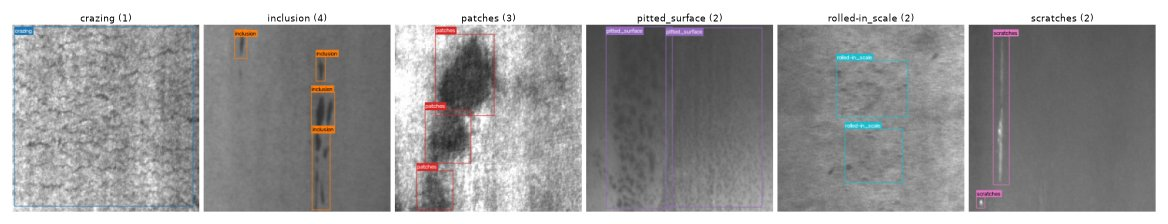

In [6]:
by_name = {Path(a.image_path).name: a for a in current}  # nom de fichier -> annotation relue au bout de la chaine
panels, titles = [], []  # vignettes et titres
for name in CLASS_NAMES:  # une image par classe
    # 1re image de la reference dont la 1re boite est de cette classe, prise dans le jeu relu
    ann = by_name[Path(next(a for a in reference if a.boxes and a.boxes[0].label == name).image_path).name]
    boxes = np.array([[b.x1, b.y1, b.x2, b.y2] for b in ann.boxes])  # coins xyxy de ses boites en tableau numpy
    labels = [CLASS_NAMES.index(b.label) for b in ann.boxes]  # indice de classe de chaque boite
    # dessine les boites ; min_side=400 agrandit l'image de 200 px pour lire les etiquettes
    panels.append(viz.draw_boxes(read_gray(ann.image_path), boxes, labels=labels, class_names=CLASS_NAMES, min_side=400))
    titles.append(f"{name} ({len(ann.boxes)})")  # titre : classe et nombre de boites
viz.grid(panels, titles, ncols=6, size=2.4)  # une ligne de 6 images

## 4. Masques -> boites, boites orientees, polygones (et retour ; etapes 2 et 3)

Convention : masque binaire (0 / 255, Magnetic Tile, MVTec) = une classe, tout pixel au-dessus de
127 est un defaut (les PNG ont souvent des bords anti-creneles a 1..254). Un objet = une
composante connexe. Trois representations, selon le modele vise :
- boite alignee (detection YOLO, Faster R-CNN) : `connectedComponentsWithStats` ;
- boite orientee (YOLO-OBB) : `minAreaRect` sur les coins des pixels : la forme naturelle d'une
  rayure ou d'une fissure en biais ;
- polygone (YOLO-seg, COCO) : `findContours` + `approxPolyDP` ; `epsilon` (pixels) simplifie le
  contour. Les trous d'un objet ne sont pas representes (RETR_EXTERNAL).

In [7]:
# renvoie les pixels (x, y) de chaque composante connexe (zone d'un seul tenant) assez grande
def mask_components(mask: np.ndarray, min_area: float = 10) -> list[np.ndarray]:
    """Pixels (x, y) de chaque composante connexe assez grande (8-connexite)."""
    binary = (mask > 127).astype(np.uint8)  # binarise : > 127 = defaut (1), sinon fond (0)
    # numerote les zones (8-connexite : les diagonales relient) ; stats donne leur surface
    count, labels, stats, _ = cv2.connectedComponentsWithStats(binary, connectivity=8)
    return [  # pour chaque composante :
        # coordonnees de ses pixels ; [::-1] remet (lignes, colonnes) en (x, y)
        np.stack(np.nonzero(labels == k)[::-1], axis=1).astype(np.float32)
        for k in range(1, count)  # composantes 1 a count - 1 (0 = le fond)
        if stats[k, cv2.CC_STAT_AREA] >= min_area  # seulement celles d'au moins min_area pixels
    ]


def mask_to_boxes(mask: np.ndarray, label: str, min_area: float = 10) -> list[Box]:  # renvoie une boite alignee par composante du masque
    # coins en BORD de pixel : x2 = dernier x + 1 (un objet d'un pixel a une largeur de 1)
    return [  # une Box par composante :
        Box(label, float(p[:, 0].min()), float(p[:, 1].min()), float(p[:, 0].max() + 1), float(p[:, 1].max() + 1))  # min / max des x et y
        for p in mask_components(mask, min_area)  # pour chaque composante connexe
    ]


# renvoie une boite orientee minimale par composante du masque
def mask_to_rotated(mask: np.ndarray, label: str, min_area: float = 10) -> list[RotatedBox]:
    boxes = []  # liste a remplir
    for p in mask_components(mask, min_area):  # pour chaque composante
        # les 4 coins de chaque pixel : chaque pixel couvre un carre de 1 x 1
        corners = np.concatenate([p, p + (1, 0), p + (0, 1), p + (1, 1)]).astype(np.float32)
        (cx, cy), (w, h), angle = cv2.minAreaRect(corners)  # plus petit rectangle tourne qui contient tous ces coins
        boxes.append(RotatedBox(label, float(cx), float(cy), float(w), float(h), float(angle)))  # converti en RotatedBox
    return boxes  # une boite orientee par composante


# renvoie un polygone par contour exterieur du masque ; epsilon (pixels) simplifie le contour
def mask_to_polygons(mask: np.ndarray, label: str, min_area: float = 10, epsilon: float = 1.0) -> list[Polygon]:
    # contours exterieurs seulement (RETR_EXTERNAL : trous ignores) ; SIMPLE : points inutiles des segments droits retires
    contours, _ = cv2.findContours((mask > 127).astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    polygons = []  # liste a remplir
    for contour in contours:  # pour chaque contour
        if cv2.contourArea(contour) < min_area:  # surface trop petite...
            continue  # ...ignore
        # approxPolyDP : simplifie le contour (ecart max epsilon pixels) ; epsilon 0 = contour brut
        approx = cv2.approxPolyDP(contour, epsilon, True) if epsilon > 0 else contour
        if len(approx) >= 3:  # au moins 3 sommets : une vraie surface
            polygons.append(Polygon(label, [(float(x), float(y)) for x, y in approx.reshape(-1, 2)]))  # sommets (x, y) en nombres decimaux
    return polygons  # un polygone par contour garde


# redessine les objets d'une annotation en masque binaire 0 / 1 ; renvoie le masque
def objects_to_mask(ann: ImageAnnotation) -> np.ndarray:
    """Retour au masque binaire (0 / 1) : pour verifier une conversion ou entrainer un segmenteur."""
    mask = np.zeros((ann.height, ann.width), np.uint8)  # masque vide de la taille de l'image
    for b in ann.boxes:  # pour chaque boite
        # rectangle plein (-1) de valeur 1 ; x2 - 1 et y2 - 1 : dernier pixel inclus
        cv2.rectangle(mask, (round(b.x1), round(b.y1)), (round(b.x2) - 1, round(b.y2) - 1), 1, -1)
    for r in ann.rotated:  # pour chaque boite orientee
        # remplit le quadrilatere de ses 4 coins (arrondis a l'entier)
        cv2.fillPoly(mask, [np.round(np.array(r.corners())).astype(np.int32)], 1)
    for p in ann.polygons:  # pour chaque polygone
        cv2.fillPoly(mask, [np.round(np.array(p.points)).astype(np.int32)], 1)  # remplit le polygone
    return mask  # renvoie le masque


tile_rows, tile_objects = [], {}  # lignes du tableau, et annotations par type de defaut
for kind in TILE_TYPES:  # pour chaque type de defaut
    label = kind[3:].lower()  # "MT_Crack" -> "crack" (retire "MT_" et passe en minuscules)
    anns = []  # annotations de ce type
    # pour chaque image .jpg du type (les .png du meme dossier sont les masques)
    for image_path in list_images(TILE_ROOT / kind / "Imgs", {".jpg"}):
        mask = read_gray(image_path.with_suffix(".png"))  # lit le masque de meme nom
        h, w = mask.shape  # taille du masque = taille de l'image
        anns.append(  # annotation de l'image avec les 3 representations :
            ImageAnnotation(  # nouvelle annotation :
                str(image_path),  # chemin de l'image
                w,  # largeur
                h,  # hauteur
                boxes=mask_to_boxes(mask, label),  # boites alignees
                rotated=mask_to_rotated(mask, label),  # boites orientees
                polygons=mask_to_polygons(mask, label),  # polygones
                mask_path=str(image_path.with_suffix(".png")),  # chemin du masque
            )
        )
    tile_objects[kind] = anns  # garde les annotations de ce type
    inter = union = 0  # intersection et union cumulees sur toutes les images
    for ann in anns:  # pour chaque image : le polygone redessine recouvre-t-il le masque d'origine ?
        truth = read_gray(ann.mask_path) > 127  # masque d'origine en booleens
        # masque redessine a partir des seuls polygones
        back = objects_to_mask(ImageAnnotation(ann.image_path, ann.width, ann.height, polygons=ann.polygons)) > 0
        # cumule les pixels communs et les pixels de l'un OU de l'autre
        inter, union = inter + int((truth & back).sum()), union + int((truth | back).sum())
    tile_rows.append(  # ligne du tableau pour ce type :
        {  # dictionnaire de la ligne
            "type": kind,  # type de defaut
            "images": len(anns),  # nombre d'images
            "boites": sum(len(a.boxes) for a in anns),  # nombre de boites alignees
            "boites orientees": sum(len(a.rotated) for a in anns),  # nombre de boites orientees
            "polygones": sum(len(a.polygons) for a in anns),  # nombre de polygones
            # nombre moyen de sommets par polygone
            "points / polygone": round(np.mean([len(p.points) for a in anns for p in a.polygons]), 1),
            # IoU = pixels communs / pixels de l'union (1 = parfait) ; max(union, 1) evite la division par 0
            "IoU masque -> polygones -> masque": round(inter / max(union, 1), 3),
        }
    )
display(pd.DataFrame(tile_rows))  # affiche le tableau

,type,images,boites,boites orientees,polygones,points / polygone,IoU masque -> polygones -> masque
0,MT_Blowhole,115,118,118,118,7.5,0.928
1,MT_Break,85,117,117,117,18.7,0.985
2,MT_Crack,57,70,70,70,14.4,0.884
3,MT_Fray,32,38,38,38,40.4,0.993
4,MT_Uneven,103,99,99,99,25.6,0.995


Le recouvrement masque -> polygones -> masque n'est pas de 1 : les composantes de moins de 10 pixels
sont ignorees, les trous perdus, et `approxPolyDP` coupe les angles. Sur des defauts FINS (fissures
de quelques pixels de large), un pixel de bord pese lourd : c'est pour cela qu'on regle `epsilon`
en regardant le tableau ci-dessous, pas a l'aveugle.

In [8]:
crack = next(a for a in tile_objects["MT_Crack"] if a.polygons)  # 1re image de fissure qui a au moins un polygone
crack_mask = read_gray(crack.mask_path)  # son masque
eps_rows = []  # lignes du tableau
for eps in (0.0, 0.5, 1.0, 2.0, 4.0):  # plusieurs valeurs d'epsilon (simplification croissante)
    polys = mask_to_polygons(crack_mask, "crack", epsilon=eps)  # polygones obtenus avec cet epsilon
    # masque redessine depuis ces polygones
    back = objects_to_mask(ImageAnnotation(crack.image_path, crack.width, crack.height, polygons=polys)) > 0
    truth = crack_mask > 127  # masque d'origine en booleens
    eps_rows.append(  # ligne du tableau :
        {  # dictionnaire de la ligne
            "epsilon": eps,  # valeur d'epsilon
            "points": sum(len(p.points) for p in polys),  # nombre total de sommets
            "IoU avec le masque": round((truth & back).sum() / (truth | back).sum(), 3),  # recouvrement avec le masque d'origine
        }
    )
print(pd.DataFrame(eps_rows).to_string(index=False))  # affiche le tableau sans numeros de ligne
print(  # affiche des lignes YOLO-OBB pour 2 boites orientees de la fissure :
    "\nlignes YOLO-OBB :",  # titre
    *[  # * deplie la liste : chaque ligne devient un argument de print
        # classe 0 puis les 4 coins normalises (4 decimales)
        "0 " + " ".join(f"{min(max(x / crack.width, 0), 1):.4f} {min(max(y / crack.height, 0), 1):.4f}" for x, y in r.corners())
        for r in crack.rotated[:2]  # les 2 premieres boites orientees
    ],
    sep="\n",  # un argument par ligne
)

 epsilon  points  IoU avec le masque
     0.0     138               1.000
     0.5     117               0.994
     1.0      41               0.905
     2.0      10               0.695
     4.0       7               0.681

lignes YOLO-OBB :
0 0.4284 0.9623 0.4228 0.0002 0.4840 0.0000 0.4896 0.9620


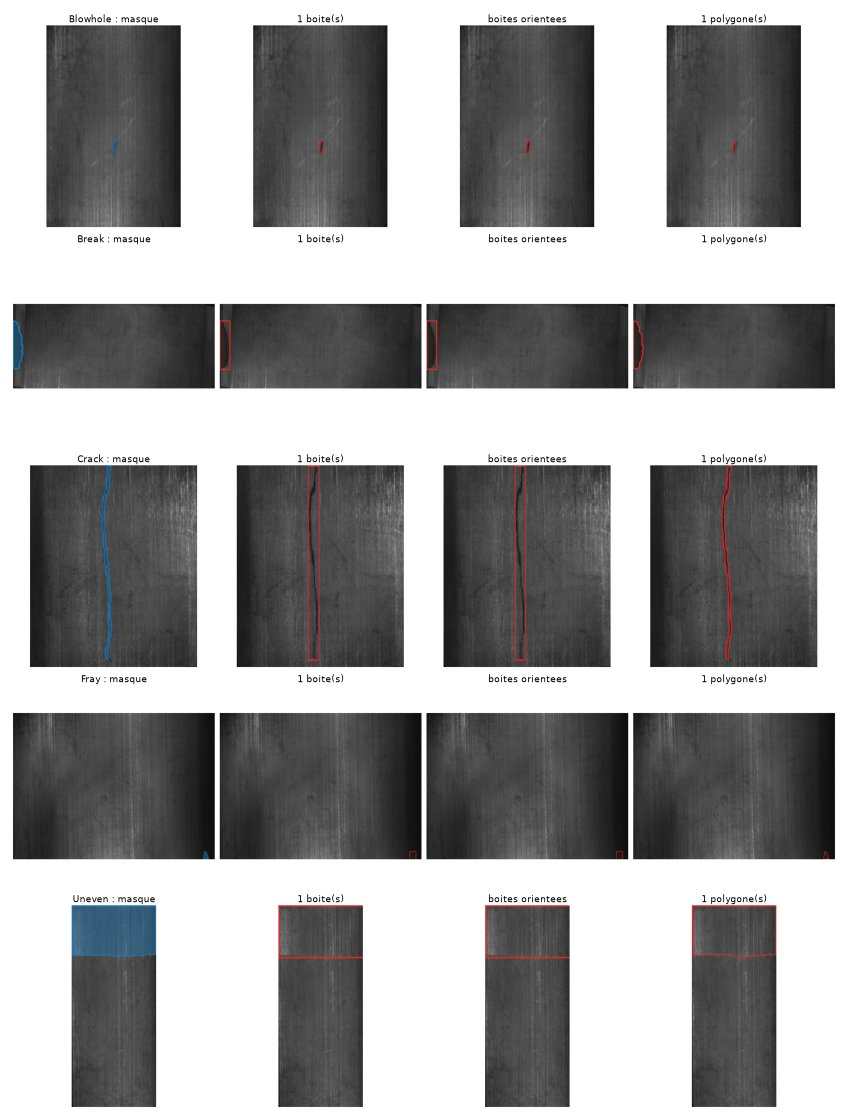

In [9]:
panels, titles = [], []  # vignettes et titres
RED = (230, 40, 40)  # couleur rouge (R, V, B) pour les dessins
for kind in TILE_TYPES:  # pour chaque type de defaut
    ann = next(a for a in tile_objects[kind] if a.polygons)  # 1re image du type qui a un polygone
    image = read_gray(ann.image_path)  # l'image
    panels.append(viz.overlay_mask(image, read_gray(ann.mask_path) > 127))  # 1) le masque superpose a l'image
    panels.append(viz.draw_boxes(image, [[b.x1, b.y1, b.x2, b.y2] for b in ann.boxes], color=RED))  # 2) les boites alignees
    # 3) les boites orientees (cx, cy, w, h, angle)
    panels.append(viz.draw_boxes(image, [[r.cx, r.cy, r.w, r.h, r.angle] for r in ann.rotated], rotated=True, color=RED))
    panels.append(viz.draw_boxes(image, None, polygons=[p.points for p in ann.polygons], color=RED))  # 4) les polygones
    # titres des 4 vignettes
    titles += [f"{kind[3:]} : masque", f"{len(ann.boxes)} boite(s)", "boites orientees", f"{len(ann.polygons)} polygone(s)"]
viz.grid(panels, titles, ncols=4, size=2.6, max_side=320)  # 4 colonnes : une ligne par type

## 5. Controler un jeu annote (etape 2)

Les erreurs les plus frequentes, toutes invisibles a l'entrainement : boites hors image ou
degenerees (x2 <= x1), boites minuscules (clic involontaire), boites en double (deux annotateurs,
deux passes), classes inconnues (faute de frappe : `scrathes`), images sans aucune annotation
(oubli ou vraie image saine ? a trancher), boites qui couvrent toute l'image.
On lance le controle sur NEU-DET tel quel, puis sur une copie ou l'on a injecte des erreurs : un
controle n'est credible que s'il retrouve ce qu'on a casse expres.

In [10]:
def box_iou(a: Box, b: Box) -> float:  # IoU de deux boites : surface commune / surface totale (0 = disjointes, 1 = identiques)
    iw = max(0.0, min(a.x2, b.x2) - max(a.x1, b.x1))  # largeur de l'intersection (0 si les boites ne se touchent pas)
    ih = max(0.0, min(a.y2, b.y2) - max(a.y1, b.y1))  # hauteur de l'intersection
    inter = iw * ih  # surface commune
    union = a.width * a.height + b.width * b.height - inter  # union = somme des surfaces - partie commune
    return inter / union if union > 0 else 0.0  # rapport ; 0 si l'union est vide


def check_annotations(  # controle un jeu annote ; signale chaque probleme trouve
    annotations: list[ImageAnnotation],  # le jeu a controler
    class_names: list[str],  # les classes autorisees
    min_size: float = 4,  # cote minimal d'une boite, en pixels
    dup_iou: float = 0.9,  # IoU au-dela duquel deux boites de meme classe sont un doublon
) -> pd.DataFrame:  # renvoie un tableau (image, probleme, detail)
    rows = []  # un tuple (image, probleme, detail) par probleme trouve
    for ann in annotations:  # pour chaque image
        name = Path(ann.image_path).name  # nom du fichier
        if not (ann.boxes or ann.rotated or ann.polygons or ann.labels):  # aucune annotation du tout...
            rows.append((name, "image sans annotation", ""))  # ...a trancher : oubli ou vraie image saine ?
        for k, b in enumerate(ann.boxes):  # pour chaque boite, avec son numero
            if b.label not in class_names:  # classe absente de la liste (faute de frappe ?)
                rows.append((name, "classe inconnue", b.label))  # note le probleme
            if b.x2 <= b.x1 or b.y2 <= b.y1:  # largeur ou hauteur nulle ou negative
                rows.append((name, "boite degeneree", f"boite {k}"))  # note le probleme
                continue  # les autres tests n'ont pas de sens pour cette boite
            if b.x1 < -1 or b.y1 < -1 or b.x2 > ann.width + 1 or b.y2 > ann.height + 1:  # deborde de l'image de plus d'un pixel
                rows.append((name, "hors image", f"boite {k}"))  # note le probleme
            if min(b.width, b.height) < min_size:  # plus petite que min_size pixels : clic involontaire ?
                rows.append((name, "minuscule", f"{b.width:.0f} x {b.height:.0f} px"))  # detail : taille en pixels
            if b.width * b.height > 0.95 * ann.width * ann.height:  # couvre plus de 95 % de l'image
                rows.append((name, "couvre toute l'image", f"boite {k}"))  # note le probleme
        for i in range(len(ann.boxes)):  # pour chaque paire de boites (i, j) avec i < j...
            for j in range(i + 1, len(ann.boxes)):  # ...chaque paire n'est vue qu'une fois
                if ann.boxes[i].label == ann.boxes[j].label and box_iou(ann.boxes[i], ann.boxes[j]) > dup_iou:  # meme classe, IoU > dup_iou
                    rows.append((name, "doublon", f"boites {i} et {j}"))  # doublon probable
    return pd.DataFrame(rows, columns=["image", "probleme", "detail"])  # tableau a 3 colonnes


# copie du jeu avec n erreurs de chaque sorte ; renvoie (copie, liste des (image, probleme) injectes)
def corrupt(annotations: list[ImageAnnotation], n: int, seed: int) -> tuple[list[ImageAnnotation], list[tuple[str, str]]]:
    """Copie du jeu avec n erreurs de chaque sorte, chacune sur une image differente ; renvoie aussi (image, probleme) injectes."""
    r = np.random.default_rng(seed)  # generateur aleatoire propre, avec graine
    # copie : nouvelles ImageAnnotation et nouvelles Box (asdict -> dict -> Box) : l'original reste intact
    copy = [ImageAnnotation(a.image_path, a.width, a.height, list(a.labels), [Box(**asdict(b)) for b in a.boxes]) for a in annotations]
    kinds = ["hors image", "minuscule", "doublon", "classe inconnue", "image sans annotation"]  # les 5 sortes d'erreurs injectees
    candidates = [k for k, a in enumerate(copy) if len(a.boxes) >= 2]  # images d'au moins 2 boites
    # n images differentes par sorte, tirees sans remise : tableau (sortes, n)
    chosen = r.choice(candidates, size=n * len(kinds), replace=False).reshape(len(kinds), n)
    injected = []  # liste des (image, probleme) injectes
    for kind, images in zip(kinds, chosen):  # pour chaque sorte et ses images
        for k in images:  # pour chaque image choisie
            a = copy[k]  # son annotation (dans la copie)
            b = a.boxes[0]  # sa 1re boite, qui sert de modele
            if kind == "hors image":  # boite poussee au-dela du bord droit
                a.boxes[0] = Box(b.label, b.x1 + 30, b.y1, a.width + 25, b.y2)  # remplace la 1re boite
            elif kind == "minuscule":  # boite minuscule...
                a.boxes.append(Box(b.label, 50, 50, 52, 53))  # ...de 2 x 3 pixels ajoutee
            elif kind == "doublon":  # doublon...
                a.boxes.append(Box(b.label, b.x1 + 1, b.y1, b.x2 + 1, b.y2))  # ...copie decalee d'un pixel ajoutee
            elif kind == "classe inconnue":  # classe inconnue...
                # ...la derniere boite recoit "scrathes" au lieu de "scratches"
                a.boxes[-1] = Box("scrathes", a.boxes[-1].x1, a.boxes[-1].y1, a.boxes[-1].x2, a.boxes[-1].y2)
            else:  # sinon : image sans annotation...
                a.boxes = []  # ...toutes ses boites retirees
            injected.append((Path(a.image_path).name, kind))  # note l'erreur injectee
    return copy, injected  # la copie abimee et la liste des erreurs


real_issues = check_annotations(reference, CLASS_NAMES)  # controle de NEU-DET tel quel
corrupted, injected = corrupt(reference, n=8, seed=SEED)  # copie avec 8 erreurs de chaque sorte
found = check_annotations(corrupted, CLASS_NAMES)  # controle de la copie
found_pairs = set(zip(found["image"], found["probleme"]))  # ensemble des (image, probleme) trouves
retrieved = [pair in found_pairs for pair in injected]  # pour chaque erreur injectee : retrouvee (True) ou non
summary = (  # tableau recapitulatif :
    pd.DataFrame(  # une colonne par source :
        {  # dictionnaire colonne -> serie
            "NEU-DET tel quel": real_issues["probleme"].value_counts(),  # problemes trouves dans le jeu brut, par sorte
            "erreurs injectees": pd.Series(Counter(kind for _, kind in injected)),  # erreurs injectees, par sorte
            "injectees retrouvees": pd.Series(Counter(kind for (_, kind), ok in zip(injected, retrieved) if ok)),  # celles retrouvees
        }
    )
    .fillna(0)  # case vide (sorte absente d'une colonne) -> 0
    .astype(int)  # en nombres entiers
)
display(summary)  # affiche le tableau

,NEU-DET tel quel,erreurs injectees,injectees retrouvees
classe inconnue,0,8,8
couvre toute l'image,54,0,0
doublon,3,8,8
hors image,0,8,8
image sans annotation,0,8,8
minuscule,0,8,8


Lecture : sur NEU-DET tel quel, les "boites qui couvrent toute l'image" sont des defauts diffus
(surtout pitted_surface) annotes par une seule grande boite : ce n'est pas une erreur, mais c'est
une information importante (la detection d'une boite par image n'apporte alors rien de plus que la
classification). Les doublons trouves dans le jeu brut sont a relire un par un.

In [11]:
display(real_issues.groupby("probleme").head(3))  # 3 exemples de chaque probleme trouve dans le jeu brut

,image,probleme,detail
0,crazing_120.jpg,doublon,boites 2 et 3
1,inclusion_62.jpg,doublon,boites 4 et 6
2,patches_198.jpg,doublon,boites 1 et 2
3,pitted_surface_136.jpg,couvre toute l'image,boite 0
4,pitted_surface_141.jpg,couvre toute l'image,boite 0
5,pitted_surface_144.jpg,couvre toute l'image,boite 0


## 6. Accord entre deux annotateurs (etape 2)

Faire annoter deux fois 5 a 10 % du jeu par deux personnes, sans qu'elles se voient. Si l'accord
entre humains est de 0,80, aucun modele ne fera durablement mieux que 0,80 sur ces etiquettes :
c'est souvent le GUIDE d'annotation qu'il faut corriger, pas le reseau.

Ici l'annotateur A est la verite de NEU-DET ; B la reproduit avec les defauts habituels : boites
decalees de quelques pixels, 5 % de defauts oublies, 3 % de fausses boites, 4 % de classes differentes.
Les boites sont appariees par l'algorithme hongrois (appariement optimal sur l'IoU), une paire
compte si IoU >= 0,5.

precision                            0.938
recall                               0.910
f1                                   0.923
IoU moyen des paires                 0.844
meme classe (boites bien placees)    0.964
kappa (classe de l'image)            0.942
accord brut (classe de l'image)      0.951


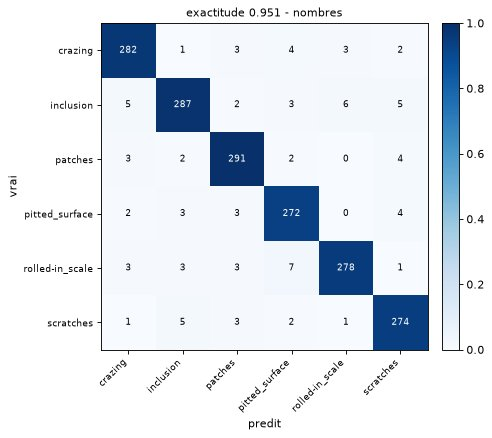

In [12]:
# apparie les boites de a et b (une pour une) ; renvoie (indice a, indice b, IoU) des paires assez recouvrantes
def match_boxes(a: list[Box], b: list[Box], iou_threshold: float = 0.5, same_label: bool = True) -> list[tuple[int, int, float]]:
    if not a or not b:  # une liste vide...
        return []  # ...aucune paire possible
    # matrice des IoU (lignes = a, colonnes = b) ; 0 si les classes different (same_label)
    iou = np.array([[box_iou(x, y) if (not same_label or x.label == y.label) else 0.0 for y in b] for x in a])
    rows, cols = linear_sum_assignment(-iou)  # algorithme hongrois : le signe - fait maximiser la somme des IoU
    # garde les paires dont l'IoU atteint le seuil
    return [(int(i), int(j), float(iou[i, j])) for i, j in zip(rows, cols) if iou[i, j] >= iou_threshold]


# accord entre deux jeux de boites : precision, rappel, F1, IoU moyen, accord de classe
def box_agreement(ref: list[ImageAnnotation], other: list[ImageAnnotation], iou_threshold: float = 0.5) -> dict:
    tp = n_ref = n_other = 0  # paires retrouvees (vrais positifs), boites de la reference, boites de l'autre jeu
    ious, same = [], []  # IoU des paires ; accord de classe des boites bien placees
    for x, y in zip(ref, other):  # pour chaque image (meme ordre dans les deux jeux)
        pairs = match_boxes(x.boxes, y.boxes, iou_threshold, same_label=True)  # paires de meme classe
        tp, n_ref, n_other = tp + len(pairs), n_ref + len(x.boxes), n_other + len(y.boxes)  # cumule les compteurs
        ious += [p[2] for p in pairs]  # garde l'IoU de chaque paire
        # paires sans regarder la classe : leur classe est-elle la meme ?
        same += [x.boxes[i].label == y.boxes[j].label for i, j, _ in match_boxes(x.boxes, y.boxes, iou_threshold, same_label=False)]
    # precision = part des boites de B retrouvees dans A ; rappel = part des boites de A retrouvees par B
    precision, recall = tp / max(n_other, 1), tp / max(n_ref, 1)
    return {  # le resultat :
        "precision": precision,  # precision
        "recall": recall,  # rappel
        "f1": 2 * precision * recall / max(precision + recall, 1e-9),  # F1 : moyenne harmonique de la precision et du rappel
        "IoU moyen des paires": float(np.mean(ious)),  # IoU moyen des paires
        "meme classe (boites bien placees)": float(np.mean(same)),  # accord de classe des boites bien placees
    }


other = []  # annotations simulees de l'annotateur B
for ann in reference:  # pour chaque image annotee par A
    boxes = []  # boites de B pour cette image
    for b in ann.boxes:  # pour chaque boite de A
        if rng.random() < 0.05:  # 5 % des cas...
            continue  # ...B oublie le defaut
        dx1, dy1, dx2, dy2 = rng.normal(0, 3, 4)  # 4 decalages tires d'une loi normale (ecart-type 3 pixels)
        # 4 % des cas : classe tiree au hasard (parfois la meme par hasard)
        label = CLASS_NAMES[rng.integers(len(CLASS_NAMES))] if rng.random() < 0.04 else b.label
        # boite de B : coins decales, ramenes dans l'image
        boxes.append(Box(label, max(0, b.x1 + dx1), max(0, b.y1 + dy1), min(ann.width, b.x2 + dx2), min(ann.height, b.y2 + dy2)))
    if rng.random() < 0.03:  # 3 % des images...
        boxes.append(Box(CLASS_NAMES[rng.integers(len(CLASS_NAMES))], 20, 20, 60, 60))  # ...B ajoute une fausse boite
    other.append(ImageAnnotation(ann.image_path, ann.width, ann.height, boxes=boxes))  # annotation de B pour cette image
agreement = box_agreement(reference, other)  # accord sur les boites
labels_a = [CLASS_NAMES.index(a.main_label()) for a in reference]  # classe principale de chaque image selon A (en indice)
# B : meme classe, sauf 6 % tiree au hasard
labels_b = [k if rng.random() > 0.06 else int(rng.integers(len(CLASS_NAMES))) for k in labels_a]
agreement["kappa (classe de l'image)"] = cohen_kappa_score(labels_a, labels_b)  # kappa de Cohen : accord corrige de celui du au hasard
# part des images ou A et B donnent la meme classe
agreement["accord brut (classe de l'image)"] = float(np.mean(np.array(labels_a) == np.array(labels_b)))
print(pd.Series(agreement).round(3).to_string())  # affiche les mesures arrondies
viz.confusion_matrix(labels_a, labels_b, CLASS_NAMES, normalize=None)  # matrice de confusion : lignes = A, colonnes = B, comptes bruts

Lecture du kappa de Cohen (accord corrige du hasard) : < 0,4 faible, 0,4 a 0,6 moyen, 0,6 a 0,8
bon, > 0,8 tres bon. La matrice dit QUELLES classes sont confondues : c'est la que le guide
d'annotation doit donner des exemples limites (photos "c'est un X, pas un Y").

Pour les masques, l'accord se mesure en IoU / Dice. Simulation : B trace le meme masque a un pixel
pres (dilate ou erode une fois au hasard). Sur des defauts fins, ce simple pixel de bord fait
chuter l'IoU : c'est un plafond pour tout segmenteur entraine sur ces masques.

In [13]:
kernel = np.ones((3, 3), np.uint8)  # noyau 3 x 3 : dilater ou eroder d'un pixel
mask_rows = []  # lignes du tableau
for kind in TILE_TYPES:  # pour chaque type de defaut
    ious = []  # IoU de chaque image
    for ann in tile_objects[kind]:  # pour chaque image
        a = (read_gray(ann.mask_path) > 127).astype(np.uint8)  # masque de A en 0 / 1
        # masque de B : A grossi (dilate) ou amaigri (erode) d'un pixel, au hasard
        b = cv2.dilate(a, kernel) if rng.random() < 0.5 else cv2.erode(a, kernel)
        union = (a | b).sum()  # pixels de A ou de B
        ious.append((a & b).sum() / union if union else 1.0)  # IoU ; 1 si les deux masques sont vides
    mask_rows.append(  # ligne du tableau :
        {  # dictionnaire de la ligne
            "type": kind,  # type de defaut
            "IoU moyen A / B": round(float(np.mean(ious)), 3),  # IoU moyen entre A et B
            # Dice = 2 x IoU / (1 + IoU) : autre mesure de recouvrement, plus indulgente
            "Dice moyen": round(float(np.mean([2 * i / (1 + i) for i in ious])), 3),
        }
    )
display(pd.DataFrame(mask_rows))  # affiche le tableau

,type,IoU moyen A / B,Dice moyen
0,MT_Blowhole,0.589,0.733
1,MT_Break,0.746,0.833
2,MT_Crack,0.540,0.690
3,MT_Fray,0.926,0.960
4,MT_Uneven,0.957,0.969


## 7. Laisser un modele designer les etiquettes suspectes (etape 2)

Principe (apprentissage confiant, simplifie) : pour chaque image, des probabilites HORS PLI,
predites par un modele qui ne l'a pas vue (validation croisee 5 plis). Une image dont la classe
donnee recoit une probabilite tres faible, alors qu'une autre classe depasse le seuil de
confiance de SA classe, est probablement mal etiquetee. Classer par perte (-log p(classe donnee))
donne le meme ordre de relecture.

Sans probabilites hors pli (predites sur le train par un modele entraine dessus), le modele a
APPRIS les erreurs et ne les signale plus : la methode ne vaut alors rien.

Demonstration sur NEU-CLS : on fausse volontairement 5 % des etiquettes et on mesure combien la
methode en retrouve. Modele : plongements resnet18 ImageNet (gele) + regression logistique.

600 images, 26 etiquettes faussees | 22 suspectes, dont 20 vraies erreurs
precision de la liste : 0.91 | erreurs retrouvees : 0.77


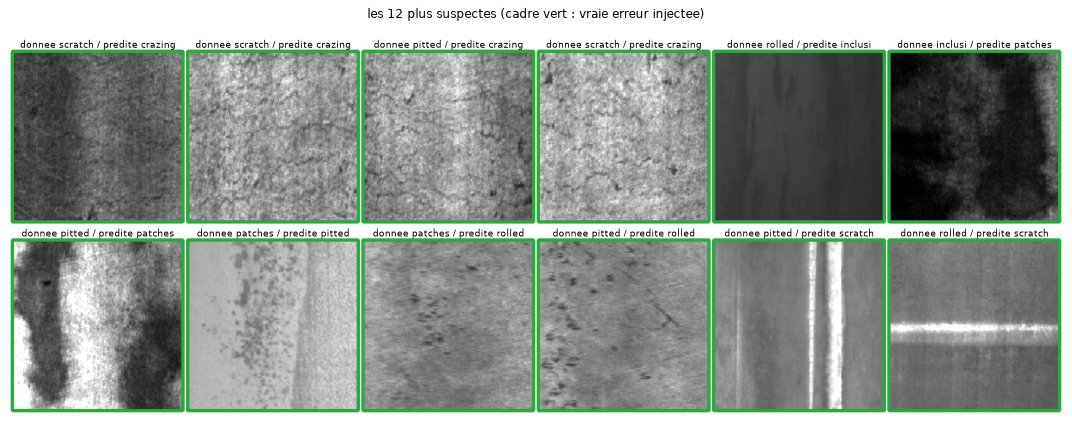

In [14]:
catalog = pd.DataFrame(  # catalogue NEU-CLS : une ligne (chemin, classe) par image
    # pour chaque sous-dossier de classe (trie) et chaque image qu'il contient
    [{"path": str(p), "label": d.name} for d in sorted(x for x in NEU_CLS.iterdir() if x.is_dir()) for p in list_images(d)]
)
if PER_CLASS:  # mode rapide...
    # ...tire PER_CLASS images par classe (graine fixe) et renumerote les lignes
    catalog = catalog.groupby("label", group_keys=False).sample(n=PER_CLASS, random_state=SEED).reset_index(drop=True)
CLS_NAMES = sorted(catalog["label"].unique())  # noms des classes, tries
y_true = catalog["label"].map(CLS_NAMES.index).to_numpy()  # vraie classe de chaque image, en indice
flipped = rng.random(len(y_true)) < NOISE_RATE  # tire 5 % des images dont l'etiquette sera faussee
y_given = y_true.copy()  # etiquettes "donnees" : une copie qu'on va abimer
# decalage de 1 a (classes - 1), modulo : toujours une AUTRE classe
y_given[flipped] = (y_true[flipped] + rng.integers(1, len(CLS_NAMES), flipped.sum())) % len(CLS_NAMES)

# resnet18 pre-entraine sur ImageNet (1,2 million de photos) : sert d'extracteur de caracteristiques
backbone = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
backbone.fc = torch.nn.Identity()  # retire la derniere couche (classification ImageNet) : sortie = vecteur de 512 valeurs
backbone = backbone.eval().to(DEVICE)  # mode evaluation (BatchNorm fige), sur GPU ou CPU
# moyenne et ecart-type ImageNet par canal (R, V, B) : la normalisation attendue par le reseau
mean, std = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1), torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)
features = []  # vecteurs de caracteristiques, lot par lot
with torch.no_grad():  # pas de calcul de gradient (utile seulement pour entrainer) : plus rapide, moins de memoire
    for start in range(0, len(catalog), 64):  # par lots de 64 images (lot = paquet d'images traitees d'un coup)
        # lit les 64 images et les redimensionne a 224 x 224 (taille d'entree du resnet)
        batch = [cv2.resize(read_gray(p), (224, 224), interpolation=cv2.INTER_AREA) for p in catalog["path"].iloc[start : start + 64]]
        # tenseur (64, 1, 224, 224) dans [0, 1], canal gris repete 3 fois (le reseau attend 3 canaux)
        x = torch.from_numpy(np.stack(batch)).float().div(255).unsqueeze(1).repeat(1, 3, 1, 1)
        # normalise, passe dans le reseau, ramene sur CPU en numpy : (64, 512)
        features.append(backbone(((x - mean) / std).to(DEVICE)).cpu().numpy())
features = np.concatenate(features)  # tous les lots en un tableau (images, 512)
# standardisation puis regression logistique ; C = 0,5 : regularisation moderee
classifier = make_pipeline(StandardScaler(), LogisticRegression(C=0.5, max_iter=3000))
# probabilites HORS PLI : chaque image est predite par un modele entraine sur les 4 autres plis
probs = cross_val_predict(classifier, features, y_given, cv=StratifiedKFold(5, shuffle=True, random_state=SEED), method="predict_proba")

self_conf = probs[np.arange(len(y_given)), y_given]  # probabilite donnee a la classe ANNONCEE de chaque image
# seuil t_j par classe : confiance moyenne des images annoncees de la classe j
thresholds = np.array([self_conf[y_given == k].mean() for k in range(len(CLS_NAMES))])
above = probs >= thresholds[None, :]  # pour chaque image et chaque classe : probabilite au-dessus du seuil de cette classe ?
above[np.arange(len(y_given)), y_given] = False  # on ignore la classe annoncee elle-meme
# suspecte : une AUTRE classe depasse son seuil et la classe predite n'est pas l'annoncee
suspect = above.any(axis=1) & (probs.argmax(1) != y_given)
table = pd.DataFrame(  # tableau de relecture :
    {  # colonnes :
        "path": catalog["path"],  # chemin de l'image
        "donnee": [CLS_NAMES[k] for k in y_given],  # classe annoncee
        "predite": [CLS_NAMES[k] for k in probs.argmax(1)],  # classe la plus probable selon le modele
        "confiance (classe donnee)": self_conf.round(3),  # probabilite de la classe annoncee
        "perte": (-np.log(np.clip(self_conf, 1e-12, 1))).round(2),  # -log(p) : grande quand p est petit (clip evite log(0))
        "suspecte": suspect,  # designee par la methode
        "vraiment fausse": flipped,  # verite (connue ici car on a fausse expres)
    }
).sort_values(["suspecte", "confiance (classe donnee)"], ascending=[False, True])  # suspectes d'abord, puis par confiance croissante
found_errors = int((suspect & flipped).sum())  # suspectes qui sont de vraies erreurs
# bilan : images, etiquettes faussees, suspectes, vraies erreurs parmi elles
print(f"{len(catalog)} images, {flipped.sum()} etiquettes faussees | {suspect.sum()} suspectes, dont {found_errors} vraies erreurs")
print(  # precision de la liste (vraies erreurs / suspectes) et part des erreurs retrouvees :
    # texte de la ligne affichee
    f"precision de la liste : {found_errors / max(suspect.sum(), 1):.2f} | erreurs retrouvees : {found_errors / max(flipped.sum(), 1):.2f}"
)
top = table.head(12)  # les 12 premieres lignes : les plus suspectes
viz.grid(  # grille des 12 images :
    [read_gray(p) for p in top["path"]],  # les images
    # titres : classe donnee / classe predite (7 lettres)
    [f"donnee {d[:7]} / predite {p[:7]}" for d, p in zip(top["donnee"], top["predite"])],
    ncols=6,  # 6 colonnes
    size=2.2,  # taille de chaque vignette (pouces)
    borders=top["vraiment fausse"].tolist(),  # cadre vert si l'etiquette etait vraiment faussee
    suptitle="les 12 plus suspectes (cadre vert : vraie erreur injectee)",  # titre general
)

En pratique, 30 a 60 % des images ainsi designees sur un vrai jeu sont de vraies erreurs : la liste
se relit en une heure au lieu de relire tout le jeu. `cleanlab` (pip install cleanlab) implemente
la version complete de la methode.

## 8. Les outils d'annotation

Outils maison de la toolbox (fenetres OpenCV, sans serveur, enregistrement a chaque touche :
relancer la commande reprend la session) :

| outil | commande | touches |
|---|---|---|
| trieuse de classes | `python recipes/annotation/scripts/sort_images.py --images <dossier> --classes ok,rayure --csv tri.csv --copy-to <jeu>` | 1-9 classe, retour arriere annuler, s passer, q quitter |
| boites a la souris | `python recipes/annotation/scripts/annotate_boxes.py --images <dossier> --classes rayure,inclusion --out boites.vtb.json` | glisser = boite, 1-9 classe courante, x / Suppr effacer la derniere, c tout effacer, n / p suivante / precedente, q quitter |
| revue des anomalies | `python recipes/annotation/scripts/review_anomalies.py --csv predictions.csv --out revue.csv` | g normal, d defaut, s passer, retour arriere annuler, q quitter |

Outils externes (tout reste sur le poste ou le reseau du site) :

| besoin | outil |
|---|---|
| annoter seul, polygones et boites orientees, aide automatique (SAM, YOLO) | X-AnyLabeling (application de bureau, format LabelMe) |
| annoter a plusieurs, toutes les taches, pre-annotations | Label Studio (serveur web local) |
| gros volumes, video, SAM integre | CVAT (Docker) |
| polygones simples, rapide a installer | LabelMe |

Conversion depuis / vers ces outils : `python recipes/annotation/scripts/convert.py --from <format>
--images <dossier> --annotations <fichier> --to <format> --out <cible> --check` (`--check` relit et
compare, comme la section 3). Guide d'annotation a remplir : `src/vtb/annotate/templates/annotation_guide_template.md`.

## 9. Resultats

In [15]:
results = {  # chiffres cles du notebook :
    # section 3 : formats relus sans aucune difference
    "conversions sans difference (sur 6)": int((conversion_table["differences"] == 0).sum()),
    "IoU masque -> polygones -> masque (moyenne des types)": round(  # section 4 : aller-retour masque -> polygones -> masque
        float(np.mean([r["IoU masque -> polygones -> masque"] for r in tile_rows])),  # moyenne des 5 types de defauts
        3,  # arrondi a 3 decimales
    ),
    # section 5 : erreurs retrouvees / erreurs injectees
    "erreurs injectees retrouvees par le controle": f"{sum(retrieved)} / {len(injected)}",
    "accord boites A / B (F1)": round(agreement["f1"], 3),  # section 6 : F1 des boites entre A et B
    "kappa classe d'image A / B": round(agreement["kappa (classe de l'image)"], 3),  # section 6 : accord sur la classe d'image
    # section 7 : vraies erreurs designees / etiquettes faussees
    "etiquettes faussees retrouvees (section 7)": f"{found_errors} / {int(flipped.sum())}",
}
display(pd.Series(results).to_frame("valeur"))  # affiche en tableau a une colonne

,valeur
conversions sans difference (sur 6),6
IoU masque -> polygones -> masque (moyenne des types),0.957
erreurs injectees retrouvees par le controle,40 / 40
accord boites A / B (F1),0.923
kappa classe d'image A / B,0.942
etiquettes faussees retrouvees (section 7),20 / 26


## 10. Passer en production

La recette `annotation` fait la meme chose en ligne de commande, avec les lecteurs et ecrivains
de `vtb.annotate` (qui gerent en plus les boites tournees et les polygones dans tous les formats,
les URL Label Studio `/data/local-files/?d=...` et les pre-annotations) :

```
python recipes/annotation/scripts/convert.py --from voc --images data/raw/neu_det/IMAGES --annotations data/raw/neu_det/ANNOTATIONS --to coco --out outputs/annotation/neu_det.coco.json --check
python recipes/annotation/scripts/convert.py --from masks --images data/raw/magnetic_tile/MT_Crack/Imgs --annotations data/raw/magnetic_tile/MT_Crack/Imgs --extensions .jpg --kind rotated --classes crack --to yolo --task obb --out outputs/annotation/mt_crack_obb --check
python recipes/annotation/scripts/agreement.py boxes --images data/raw/neu_det/IMAGES --a voc:annotateur_a --b coco:annotateur_b.json
```

Controle : la toolbox relit NEU-DET a l'identique du notebook, relit le COCO ecrit par le notebook,
et convertit les masques en objets exactement comme ici.

In [16]:
from vtb.annotate.check import same_annotations  # compare deux jeux d'annotations, renvoie les differences
from vtb.annotate.formats import read_annotations  # lecteur de la toolbox pour tous les formats
from vtb.annotate.masks import mask_to_polygons as vtb_mask_to_polygons  # version toolbox, renommee pour ne pas ecraser celle du notebook
from vtb.annotate.masks import mask_to_rotated_boxes as vtb_mask_to_rotated  # idem pour les boites orientees
from vtb.annotate.schema import ImageAnnotation as VtbAnnotation  # format pivot de la toolbox (memes champs)

production = read_annotations("voc", NEU_IMAGES, NEU_XML)  # NEU-DET lu par la toolbox
mine = [VtbAnnotation.from_dict(asdict(a)) for a in reference]  # nos annotations converties au format de la toolbox (via un dict)
check_voc = same_annotations(production, mine, tol=1e-6)  # differences toolbox / notebook (tolerance 1e-6 pixel)
# le COCO ecrit par ce notebook, relu par la toolbox, compare a la reference
check_coco = same_annotations(production, read_annotations("coco", NEU_IMAGES, OUT / "neu_det.coco.json"), tol=1e-2)
mask_ok = True  # devient False au premier ecart
for ann in tile_objects["MT_Crack"][:20]:  # 20 images de fissures
    mask = read_gray(ann.mask_path)  # lit le masque
    theirs = vtb_mask_to_polygons(mask, ["crack"])  # polygones calcules par la toolbox
    mask_ok &= [p.points for p in theirs] == [p.points for p in ann.polygons]  # memes sommets que ceux du notebook ?
    theirs_r = vtb_mask_to_rotated(mask, ["crack"])  # boites orientees de la toolbox
    # memes centre, taille et angle (aux arrondis pres, np.allclose) ?
    mask_ok &= all(np.allclose([r.cx, r.cy, r.w, r.h, r.angle], [s.cx, s.cy, s.w, s.h, s.angle]) for r, s in zip(theirs_r, ann.rotated))
print("VOC lu par la toolbox == notebook :", not check_voc, f"({len(check_voc)} differences)")  # liste vide = aucune difference = True
print("COCO du notebook relu par la toolbox == reference :", not check_coco, f"({len(check_coco)} differences)")  # idem pour le COCO
print("masques -> polygones / boites orientees identiques :", mask_ok)  # verdict des conversions de masques
assert not check_voc and not check_coco and mask_ok  # arrete le notebook avec une erreur si un controle echoue

VOC lu par la toolbox == notebook : True (0 differences)
COCO du notebook relu par la toolbox == reference : True (0 differences)
masques -> polygones / boites orientees identiques : True


## Pour aller plus loin

- Pre-annoter avec un premier modele (`recipes/annotation/scripts/preannotate.py`) puis relire
  dans l'ordre d'incertitude : 3 a 5 fois plus rapide qu'annoter de zero.
- Ecrire le guide d'annotation AVANT d'annoter (exemples limites en photo), mesurer l'accord sur
  50 images, corriger le guide, puis seulement annoter le reste.
- Relancer la section 7 apres chaque grosse campagne d'annotation.